In [9]:
import pandas as pd

df = pd.read_csv('Twitter_Emotion_Dataset.csv')
df_kamus = pd.read_csv('kamus_singkatan.csv', sep=';', header=None, names=['slang', 'baku'])

kamus_singkatan = dict(zip(df_kamus['slang'], df_kamus['baku']))

print(df.head())

   label                                              tweet
0  anger  Soal jln Jatibaru,polisi tdk bs GERTAK gubernu...
1  anger  Sesama cewe lho (kayaknya), harusnya bisa lebi...
2  happy  Kepingin gudeg mbarek Bu hj. Amad Foto dari go...
3  anger  Jln Jatibaru,bagian dari wilayah Tn Abang.Peng...
4  happy  Sharing pengalaman aja, kemarin jam 18.00 bata...


In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

X = df['tweet']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Inisialisasi dictionary singkatan, stopwords, dan stemmer
kamus_singkatan = dict(zip(df_kamus['slang'], df_kamus['baku']))
stop_words = set(stopwords.words('indonesian'))
stemmer = StemmerFactory().create_stemmer()

# Fungsi Praproses
def preprocess_text(text):
    # Case folding
    text = text.lower()
    # Hapus tag khusus & karakter selain huruf
    text = re.sub(r'\[username\]|\[url\]', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    
    # Normalisasi kata slang
    words = text.split()
    words = [kamus_singkatan.get(w, w) for w in words]
    text = ' '.join(words)
    
    # Tokenisasi dan Stopword removal
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words]
    
    # Stemming
    return ' '.join(stemmer.stem(w) for w in tokens)

# Terapkan hasil praproses pada data latih dan uji
X_train_clean = X_train.apply(preprocess_text)
X_test_clean = X_test.apply(preprocess_text)

print("Data latih:", len(X_train))
print("Data uji:", len(X_test))
print("\nSebelum:", X_train.iloc[0])
print("Sesudah:", X_train_clean.iloc[0])

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Data latih: 3520
Data uji: 881

Sebelum: Dulu WA buat pacaran, isinya foto2 selfie dan aktivitas pacar, penunjang LDR.. Sekarang pacarnya hilang, foto-foto diganti sama foto pencitraan orang kerja di lapangan dan preview desain...
Sesudah: pacar isi foto selfie aktivitas pacar tunjang ldr pacar hilang fotofoto ganti foto citra orang kerja lapang preview desain


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

# Fit dan transform hanya pada data latih untuk menghindari data leakage
X_train_tfidf = vectorizer.fit_transform(X_train_clean)

# Hanya transform pada data uji
X_test_tfidf = vectorizer.transform(X_test_clean)

print("Matriks TF-IDF latih:", X_train_tfidf.shape)
print("Matriks TF-IDF uji:", X_test_tfidf.shape)

Matriks TF-IDF latih: (3520, 12293)
Matriks TF-IDF uji: (881, 12293)


In [4]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Menggunakan 2 algoritma: Naive Bayes dan Support Vector Machine (Linear)
models = {
    'Naive Bayes': MultinomialNB(),
    'SVM': SVC(kernel='linear', random_state=42)
}

hasil = {}

# Melatih model, memprediksi, dan mencetak laporan kinerja
for nama, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    hasil[nama] = pred
    
    print(f"\n=== {nama} ===")
    print(classification_report(y_test, pred))


=== Naive Bayes ===
              precision    recall  f1-score   support

       anger       0.59      0.82      0.69       220
        fear       0.93      0.39      0.55       130
       happy       0.60      0.61      0.60       204
        love       0.97      0.45      0.61       127
     sadness       0.45      0.57      0.51       200

    accuracy                           0.60       881
   macro avg       0.71      0.57      0.59       881
weighted avg       0.66      0.60      0.60       881


=== SVM ===
              precision    recall  f1-score   support

       anger       0.58      0.71      0.64       220
        fear       0.86      0.63      0.73       130
       happy       0.56      0.55      0.55       204
        love       0.85      0.75      0.79       127
     sadness       0.48      0.48      0.48       200

    accuracy                           0.61       881
   macro avg       0.66      0.62      0.64       881
weighted avg       0.63      0.61      0.62

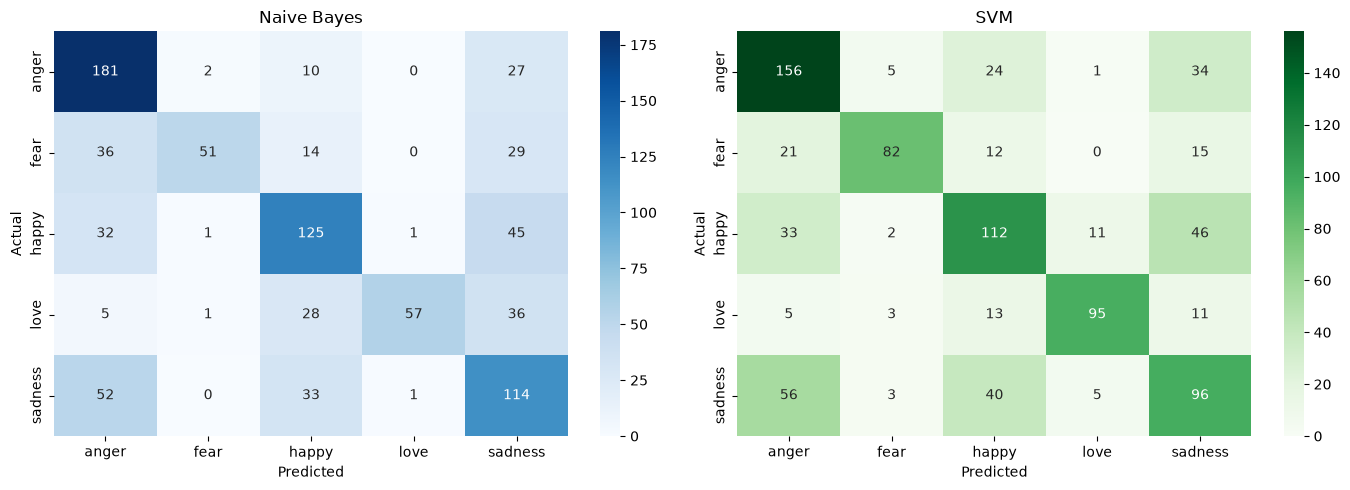

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

labels = sorted(y.unique())

# Membuat visualisasi Confusion Matrix bersebelahan (1 baris, 2 kolom)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (nama, pred) in zip(axes, hasil.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    
    warna_grafik = 'Greens' if nama == 'SVM' else 'Blues'
    
    sns.heatmap(cm, annot=True, fmt='d', cmap=warna_grafik,
                xticklabels=labels, yticklabels=labels, ax=ax)
    
    ax.set_title(nama)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()